# TP : Classification d'images CIFAR-10 — MLP vs CNN (corrigé)

Notebook de solution : exercices 1 à 6, bonus et questions de réflexion.
Un GPU est fortement conseillé (Colab, Kaggle). Sur CPU, mettez `RUN_BONUS = False` pour gagner du temps.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

keras.utils.set_random_seed(42)

# Interrupteurs pour les parties longues
RUN_BONUS       = True    # augmentation, BatchNorm, GAP, MLP 5 M
RUN_TRANSFER    = True    # MobileNetV2 (télécharge les poids ImageNet)
RUN_PERMUTATION = True    # question de réflexion 4 (pixels permutés)

results = {}   # collecte des résultats pour le tableau comparatif
print("TensorFlow", tf.__version__, "| GPU :", tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU : []


## Exercice 1 — Chargement et exploration

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

CLASSES = ['avion', 'automobile', 'oiseau', 'chat', 'cerf',
           'chien', 'grenouille', 'cheval', 'bateau', 'camion']

# 2. shape et dtype
for nom, arr in [('x_train', x_train_full), ('y_train', y_train_full),
                 ('x_test', x_test), ('y_test', y_test)]:
    print(f"{nom:8s} shape={arr.shape}  dtype={arr.dtype}")

# 3. valeurs min / max des pixels
print("Pixels : min =", x_train_full.min(), "| max =", x_train_full.max())

# 4. équilibre des classes
print("Images par classe (train) :", np.bincount(y_train_full.ravel()))
print("Images par classe (test)  :", np.bincount(y_test.ravel()))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1585s 9us/step
x_train  shape=(50000, 32, 32, 3)  dtype=uint8
y_train  shape=(50000, 1)  dtype=uint8
x_test   shape=(10000, 32, 32, 3)  dtype=uint8
y_test   shape=(10000, 1)  dtype=uint8
Pixels : min = 0 | max = 255
Images par classe (train) : [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
Images par classe (test)  : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


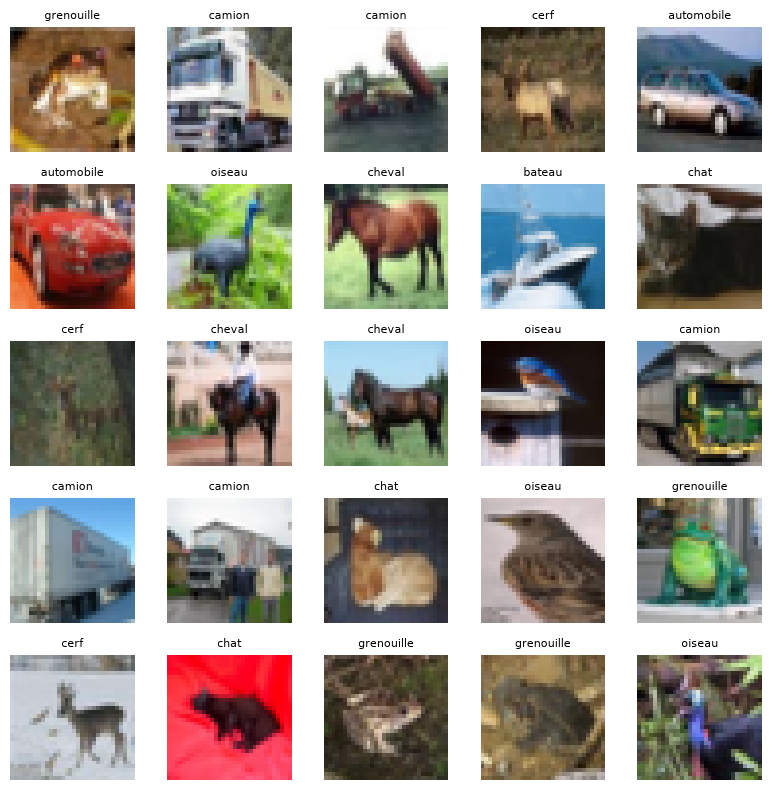

In [3]:
# 5. grille 5x5
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train_full[i])
    plt.title(CLASSES[y_train_full[i, 0]], fontsize=8)
    plt.axis('off')
plt.tight_layout(); plt.show()

**Q6 — Dimension d'une image aplatie ? Que perd-on ?**
32 × 32 × 3 = **3072** valeurs. En aplatissant, on perd la **structure spatiale 2D** : le modèle ne sait plus quels pixels sont voisins (ni quels canaux appartiennent au même pixel).
Résultats attendus : `(50000, 32, 32, 3)` en `uint8`, pixels entre 0 et 255, 5000 images par classe en entraînement et 1000 en test (classes équilibrées).

## Exercice 2 — Prétraitement

In [4]:
# 1. float32 et normalisation dans [0, 1]
x_train_full = x_train_full.astype('float32') / 255.0
x_test       = x_test.astype('float32') / 255.0

# 2. labels (N,1) -> (N,)
y_train_full = y_train_full.ravel()
y_test       = y_test.ravel()

# 3. découpage 45 000 / 5 000
x_train, x_val = x_train_full[:45000], x_train_full[45000:]
y_train, y_val = y_train_full[:45000], y_train_full[45000:]
print(x_train.shape, x_val.shape, x_test.shape)

(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


**Q4 — Pourquoi ne jamais utiliser le test pour choisir les hyperparamètres ou arrêter l'entraînement ?**
Le jeu de test doit rester une estimation **non biaisée** de la généralisation. S'en servir pour régler le modèle (hyperparamètres, arrêt précoce) revient à « apprendre » sur le test : la précision annoncée serait **optimiste**. On utilise donc le jeu de validation pour ces choix et on ne touche au test qu'une seule fois, à la fin.

**Q5 — `sparse_categorical_crossentropy` vs `categorical_crossentropy` ?**
`sparse_categorical_crossentropy` attend des labels **entiers** (0 à 9) ; `categorical_crossentropy` attend des vecteurs **one-hot**. Le calcul de la perte est identique ; la version *sparse* évite de stocker les vecteurs one-hot.

## Exercice 3 — Modèle de référence : MLP

**Calcul à la main** (Dense : entrées × sorties + sorties) :

| Couche | Sortie | Paramètres |
|---|---|---|
| Input | (32, 32, 3) | 0 |
| Flatten | (3072) | 0 |
| Dense 512, ReLU | (512) | 3072 × 512 + 512 = **1 573 376** |
| Dropout 0.3 | (512) | 0 |
| Dense 256, ReLU | (256) | 512 × 256 + 256 = **131 328** |
| Dropout 0.3 | (256) | 0 |
| Dense 10, Softmax | (10) | 256 × 10 + 10 = **2 570** |
| **Total** | | **1 707 274** |

In [5]:
def build_mlp(name='MLP', widths=(512, 256), dropout=0.3):
    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(32, 32, 3)))
    model.add(layers.Flatten())
    for w in widths:
        model.add(layers.Dense(w, activation='relu'))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Vérification du calcul à la main
def dense_params(n_in, n_out): return n_in * n_out + n_out

attendu_mlp = dense_params(3072, 512) + dense_params(512, 256) + dense_params(256, 10)
mlp = build_mlp()
mlp.summary()
print("Attendu à la main :", attendu_mlp, "| model.count_params() :", mlp.count_params())
assert attendu_mlp == mlp.count_params() == 1_707_274

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

Attendu à la main : 1707274 | model.count_params() : 1707274


In [6]:
EPOCHS, BATCH = 30, 64

def train(model, data=None, epochs=EPOCHS, tag=None):
    # Entraîne un modèle (mêmes réglages pour tous) et renvoie (history, durée, acc test)
    xtr, ytr, xva, yva, xte, yte = data if data else (x_train, y_train, x_val, y_val, x_test, y_test)
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5,
                                               restore_best_weights=True)]
    t0 = time.time()
    history = model.fit(xtr, ytr, validation_data=(xva, yva),
                        epochs=epochs, batch_size=BATCH,
                        callbacks=callbacks, verbose=2)
    duree = time.time() - t0
    _, acc = model.evaluate(xte, yte, verbose=0)
    key = tag or model.name
    results[key] = dict(params=model.count_params(), acc=acc, time=duree,
                        epochs=len(history.history['loss']))
    print(f"==> {key}: acc test = {acc:.4f} | temps = {duree:.1f} s | "
          f"epoques = {len(history.history['loss'])}")
    return history, duree, acc

h_mlp, t_mlp, acc_mlp = train(mlp)

Epoch 1/30
704/704 - 13s - 18ms/step - accuracy: 0.2450 - loss: 2.0331 - val_accuracy: 0.3194 - val_loss: 1.8806
Epoch 2/30
704/704 - 16507s - 23s/step - accuracy: 0.2966 - loss: 1.9046 - val_accuracy: 0.3386 - val_loss: 1.8188
Epoch 3/30
704/704 - 12s - 17ms/step - accuracy: 0.3127 - loss: 1.8662 - val_accuracy: 0.3288 - val_loss: 1.8252
Epoch 4/30
704/704 - 12s - 16ms/step - accuracy: 0.3206 - loss: 1.8483 - val_accuracy: 0.3498 - val_loss: 1.8211
Epoch 5/30
704/704 - 12s - 17ms/step - accuracy: 0.3274 - loss: 1.8404 - val_accuracy: 0.3424 - val_loss: 1.8231
Epoch 6/30
704/704 - 12s - 17ms/step - accuracy: 0.3371 - loss: 1.8170 - val_accuracy: 0.3450 - val_loss: 1.8043
Epoch 7/30
704/704 - 13s - 18ms/step - accuracy: 0.3394 - loss: 1.8074 - val_accuracy: 0.3734 - val_loss: 1.7634
Epoch 8/30
704/704 - 19s - 28ms/step - accuracy: 0.3499 - loss: 1.7860 - val_accuracy: 0.3698 - val_loss: 1.7593
Epoch 9/30


KeyboardInterrupt: 

## Exercice 4 — Réseau convolutif (CNN)

**Calcul à la main** (Conv2D : (kh · kw · Cin + 1) · Cout ; `padding='same'` conserve la taille, MaxPool 2×2 la divise par 2) :

| Couche | Sortie | Calcul | Paramètres |
|---|---|---|---|
| Conv2D 32 | (32,32,32) | (3·3·3+1)×32 | 896 |
| Conv2D 32 | (32,32,32) | (3·3·32+1)×32 | 9 248 |
| MaxPool 2×2 + Dropout | (16,16,32) | – | 0 |
| Conv2D 64 | (16,16,64) | (3·3·32+1)×64 | 18 496 |
| Conv2D 64 | (16,16,64) | (3·3·64+1)×64 | 36 928 |
| MaxPool 2×2 + Dropout | (8,8,64) | – | 0 |
| Flatten | (4096) | 8·8·64 | 0 |
| Dense 256 | (256) | 4096×256+256 | 1 048 832 |
| Dropout 0.5 | (256) | – | 0 |
| Dense 10 | (10) | 256×10+10 | 2 570 |
| **Total** | | | **1 116 970** |

In [ ]:
def build_cnn(name='CNN', augment=False, bn=False, gap=False):
    # augment : RandomFlip + RandomTranslation (bonus) ; bn : BatchNorm ; gap : GlobalAveragePooling
    def conv_block(model, filters):
        for _ in range(2):
            if bn:
                model.add(layers.Conv2D(filters, 3, padding='same'))
                model.add(layers.BatchNormalization())
                model.add(layers.Activation('relu'))
            else:
                model.add(layers.Conv2D(filters, 3, padding='same', activation='relu'))
        model.add(layers.MaxPooling2D(2))
        model.add(layers.Dropout(0.25))

    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=(32, 32, 3)))
    if augment:
        model.add(layers.RandomFlip('horizontal'))
        model.add(layers.RandomTranslation(0.1, 0.1))
    conv_block(model, 32)
    conv_block(model, 64)
    model.add(layers.GlobalAveragePooling2D() if gap else layers.Flatten())
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def conv_params(k, c_in, c_out): return (k * k * c_in + 1) * c_out

conv_total = (conv_params(3, 3, 32) + conv_params(3, 32, 32) +
              conv_params(3, 32, 64) + conv_params(3, 64, 64))
attendu_cnn = conv_total + dense_params(8 * 8 * 64, 256) + dense_params(256, 10)

cnn = build_cnn()
cnn.summary()
print("Convolutions seules :", conv_total, f"({conv_total / attendu_cnn:.1%} du total)")
print("Attendu à la main   :", attendu_cnn, "| model.count_params() :", cnn.count_params())
assert attendu_cnn == cnn.count_params() == 1_116_970

**2. Comparaison avec le MLP.** Le CNN a **≈ 35 % de paramètres en moins** (1,12 M contre 1,71 M) alors qu'il est plus profond. C'est surprenant au premier abord : les 4 convolutions ne totalisent que 65 568 paramètres (≈ 6 %) ; **94 % des poids sont dans `Dense(256)`** après le Flatten.

**3. Champ récepteur** (récurrence r_l = r_{l-1} + (k_l − 1)·j_{l-1}, j_l = j_{l-1}·s_l, avec r_0 = j_0 = 1) :

| Couche | k | s | saut j | champ récepteur r |
|---|---|---|---|---|
| Conv 3×3 | 3 | 1 | 1 | 3 |
| Conv 3×3 | 3 | 1 | 1 | 5 |
| MaxPool 2×2 | 2 | 2 | 2 | 6 |
| Conv 3×3 | 3 | 1 | 2 | 10 |
| Conv 3×3 | 3 | 1 | 2 | 14 |
| MaxPool 2×2 | 2 | 2 | 4 | **16** |

Après le second MaxPool, chaque neurone de la carte 8×8×64 « voit » une zone de **16 × 16 pixels**.

In [ ]:
# Vérification du champ récepteur par code
def receptive_field(couches):
    r, j = 1, 1
    for k, s in couches:
        r = r + (k - 1) * j
        j = j * s
        print(f"k={k} s={s} -> r={r}, saut={j}")
    return r

print("Champ récepteur final :", receptive_field([(3,1), (3,1), (2,2), (3,1), (3,1), (2,2)]))

In [ ]:
# 4. entraînement avec EXACTEMENT les mêmes réglages que le MLP
h_cnn, t_cnn, acc_cnn = train(cnn)

## Exercice 5 — Comparaison MLP vs CNN

In [ ]:
# 1. Tableau comparatif
res = pd.DataFrame({
    'Modèle':      ['MLP', 'CNN'],
    '# paramètres': [mlp.count_params(), cnn.count_params()],
    'Acc. test':   [round(acc_mlp, 4), round(acc_cnn, 4)],
    'Temps total (s)': [round(t_mlp, 1), round(t_cnn, 1)],
    '# époques':   [len(h_mlp.history['loss']), len(h_cnn.history['loss'])]})
display(res)

In [ ]:
# 2. Courbes de précision et de perte sur une même figure
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for h, nom in [(h_mlp, 'MLP'), (h_cnn, 'CNN')]:
    ax[0].plot(h.history['accuracy'], '--', label=f'{nom} train')
    ax[0].plot(h.history['val_accuracy'], label=f'{nom} val')
    ax[1].plot(h.history['loss'], '--', label=f'{nom} train')
    ax[1].plot(h.history['val_loss'], label=f'{nom} val')
for a, t in zip(ax, ['Précision', 'Perte']):
    a.set_title(t); a.set_xlabel('Époque'); a.legend(); a.grid(True)
plt.tight_layout(); plt.savefig('mlp_vs_cnn.png', dpi=200); plt.show()

# Quel modèle sur-apprend le plus ? écart train - val à la meilleure époque
for h, nom in [(h_mlp, 'MLP'), (h_cnn, 'CNN')]:
    b = int(np.argmax(h.history['val_accuracy']))
    ecart = h.history['accuracy'][b] - h.history['val_accuracy'][b]
    print(f"{nom}: meilleure époque {b+1} | acc train {h.history['accuracy'][b]:.3f} | "
          f"acc val {h.history['val_accuracy'][b]:.3f} | écart {ecart:+.3f}")

**Lequel sur-apprend le plus ?** Le **MLP** : sa précision d'entraînement continue de monter alors que sa validation plafonne vite (≈ 50–55 %), donc l'écart train/val se creuse et la perte de validation remonte tôt. Le CNN, régularisé par les Dropout (0.25 / 0.5) et par ses poids partagés, garde un écart modéré. *(Vérifiez avec l'écart affiché ci-dessus.)*

In [ ]:
# 3. Matrices de confusion sur le test
preds = {}
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, model in zip(ax, [mlp, cnn]):
    y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
    preds[model.name] = y_pred
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=CLASSES, normalize='true',
        values_format='.2f', xticks_rotation=45, ax=a, colorbar=False)
    a.set_title(model.name)
    print(model.name); print(classification_report(y_test, y_pred, target_names=CLASSES))
plt.tight_layout(); plt.show()

# Paires de classes les plus confondues
def top_confusions(y_true, y_pred, k=5):
    cm = confusion_matrix(y_true, y_pred)
    np.fill_diagonal(cm, 0)
    pairs = []
    for i in range(10):
        for j in range(i + 1, 10):
            pairs.append((cm[i, j] + cm[j, i], CLASSES[i], CLASSES[j]))
    return sorted(pairs, reverse=True)[:k]

for nom, y_pred in preds.items():
    print(f"Paires les plus confondues ({nom}) :")
    for n, a, b in top_confusions(y_test, y_pred):
        print(f"   {a} <-> {b} : {n} erreurs")

**Cohérence des confusions.** Les paires typiquement les plus confondues sont **chat ↔ chien**, **automobile ↔ camion**, **cerf ↔ cheval**, **avion ↔ oiseau/bateau** (fond bleu commun) : ce sont des classes visuellement proches, c'est cohérent. Le MLP confond en plus des classes qui partagent des **couleurs globales** similaires : il apprend surtout des statistiques de couleur, pas des formes.

In [ ]:
# 4. 10 images de test avec prédictions MLP et CNN
p_mlp = mlp.predict(x_test[:10], verbose=0).argmax(1)
p_cnn = cnn.predict(x_test[:10], verbose=0).argmax(1)
plt.figure(figsize=(15, 3.2))
for i in range(10):
    plt.subplot(1, 10, i + 1); plt.imshow(x_test[i]); plt.axis('off')
    plt.title(f"Vrai: {CLASSES[y_test[i]]}\nMLP: {CLASSES[p_mlp[i]]}\n"
              f"CNN: {CLASSES[p_cnn[i]]}", fontsize=7)
plt.tight_layout(); plt.show()

**Résultats attendus (ordres de grandeur)** : MLP ≈ 50–55 %, CNN ≈ 75–79 %, soit ≈ 25 points de gain avec moins de paramètres. Une époque de CNN coûte plus cher en calcul (convolutions sur 32×32) mais reste rapide sur GPU.

## Exercice 6 — Robustesse à la translation

In [ ]:
# 1. Décalage horizontal (axe 2 = largeur pour des images (N, H, W, C))
def shift(x, d):
    return np.roll(x, shift=d, axis=2)

# 2. Évaluation pour d dans {0, 2, 4, 6, 8}
decalages = [0, 2, 4, 6, 8]
acc_shift = {'MLP': [], 'CNN': []}
for d in decalages:
    xs = shift(x_test, d)
    acc_shift['MLP'].append(mlp.evaluate(xs, y_test, verbose=0)[1])
    acc_shift['CNN'].append(cnn.evaluate(xs, y_test, verbose=0)[1])

for nom, v in acc_shift.items():
    plt.plot(decalages, v, 'o-', label=nom)
plt.xlabel('Décalage horizontal (pixels)'); plt.ylabel('Précision test')
plt.title('Robustesse à la translation'); plt.legend(); plt.grid(True); plt.show()
display(pd.DataFrame(acc_shift, index=decalages).round(4))

**3. Quel modèle est le plus robuste ?** Le **CNN**. Dans le MLP, chaque poids est lié à une **position fixe** de pixel : décaler l'image revient à lui présenter une entrée « nouvelle » et la précision chute vite. Dans le CNN, la convolution est **équivariante** par translation (le même filtre est appliqué partout) et le MaxPooling apporte une **invariance locale**.

**4. Le CNN est-il parfaitement invariant ? Non.**
- Les convolutions sont équivariantes, mais **Flatten + Dense** associe à nouveau un poids à chaque **position** de la carte 8×8 : l'invariance est perdue au niveau du classifieur.
- Le MaxPool de pas 2 n'est invariant qu'aux petits décalages (le résultat dépend de la parité du décalage).
- Les bords (padding, `np.roll` qui fait « reboucler » l'image) introduisent aussi des différences.

**Modification proposée** : remplacer `Flatten` par `GlobalAveragePooling2D()` (moyenne de chaque carte sur toutes les positions → invariance globale accrue). `Dense(256)` passe de 1 048 832 à 64 × 256 + 256 = 16 640 paramètres (modèle total ≈ 85 k). En contrepartie, il faut souvent des blocs convolutifs plus profonds pour conserver la précision.

## Bonus — Pour aller plus loin

1. Augmentation de données (`RandomFlip`, `RandomTranslation`)
2. Batch Normalization
3. `GlobalAveragePooling2D` à la place de `Flatten`
4. MLP « équitable » (≈ 5 M de paramètres)
5. Transfer learning (MobileNetV2, 96×96)

In [ ]:
if RUN_BONUS:
    # 1. Augmentation (prévoir plus d'époques : convergence plus lente)
    cnn_aug = build_cnn(name='CNN_aug', augment=True)
    h_aug, t_aug, acc_aug = train(cnn_aug, epochs=50)

    # Les couches Random* sont l'identité hors entraînement
    xb = x_val[:4]
    same = np.allclose(cnn_aug.layers[0](xb, training=False), xb)
    print("Augmentation inactive à l'inférence :", same)

In [ ]:
if RUN_BONUS:
    # 2. Batch Normalization après chaque convolution
    cnn_bn = build_cnn(name='CNN_BN', bn=True)
    h_bn, t_bn, acc_bn = train(cnn_bn)

    plt.plot(h_cnn.history['val_accuracy'], label='CNN val')
    plt.plot(h_bn.history['val_accuracy'], label='CNN + BatchNorm val')
    plt.xlabel('Époque'); plt.ylabel('Précision validation'); plt.legend(); plt.grid(True)
    plt.title('Effet de la Batch Normalization'); plt.show()

In [ ]:
if RUN_BONUS:
    # 3. GlobalAveragePooling2D à la place de Flatten
    cnn_gap = build_cnn(name='CNN_GAP', gap=True)
    print("Paramètres CNN_GAP :", cnn_gap.count_params(), "(attendu ≈ 84 778)")
    h_gap, t_gap, acc_gap = train(cnn_gap)

In [ ]:
if RUN_BONUS:
    # 4. MLP « équitable » : ≈ 5 M de paramètres
    mlp_big = build_mlp(name='MLP_5M', widths=(1024, 1024, 512))
    print("Paramètres MLP_5M :", mlp_big.count_params())
    h_big, t_big, acc_big = train(mlp_big)

In [ ]:
if RUN_BONUS:
    # Robustesse à la translation des variantes du CNN
    modeles = {'MLP': mlp, 'CNN': cnn}
    for nom in ['cnn_aug', 'cnn_bn', 'cnn_gap']:
        if nom in globals(): modeles[nom] = globals()[nom]
    for nom, m in modeles.items():
        accs = [m.evaluate(shift(x_test, d), y_test, verbose=0)[1] for d in decalages]
        plt.plot(decalages, accs, 'o-', label=nom)
    plt.xlabel('Décalage horizontal (pixels)'); plt.ylabel('Précision test')
    plt.legend(); plt.grid(True); plt.title('Robustesse : variantes du CNN'); plt.show()

In [ ]:
if RUN_TRANSFER:
    # 5. Transfer learning : MobileNetV2 pré-entraîné sur ImageNet, images 96x96
    base = keras.applications.MobileNetV2(input_shape=(96, 96, 3),
                                          include_top=False, weights='imagenet')
    base.trainable = False

    mobilenet = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Resizing(96, 96),
        layers.Rescaling(2.0, offset=-1.0),     # [0,1] -> [-1,1]
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.2),
        layers.Dense(10, activation='softmax'),
    ], name='MobileNetV2')
    mobilenet.compile(optimizer=keras.optimizers.Adam(1e-3),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h_mob, t_mob, acc_mob = train(mobilenet, epochs=10)

**Réponses aux questions du bonus**
- **Augmentation** : gain d'environ +3 à +5 points (≈ 80–83 %). L'écart train/val diminue et la validation progresse plus longtemps (régularisation). On ne l'applique **pas à la validation** : on veut évaluer le modèle sur des images **réelles, non déformées** (les couches `Random*` sont d'ailleurs l'identité à l'inférence).
- **Batch Normalization** : convergence plus rapide (moins d'époques pour atteindre une bonne précision), learning rate plus élevé possible, gain typique de quelques points.
- **GlobalAveragePooling2D** : ≈ 85 k paramètres au lieu de 1,12 M, pour une précision proche ou légèrement inférieure ; meilleure invariance à la translation.
- **MLP à 5 M de paramètres** : l'écart avec le CNN **ne se réduit presque pas** (le MLP gagne au mieux quelques points et sur-apprend davantage) : ce n'est pas le nombre de paramètres qui fait la performance, mais le biais inductif.
- **Transfer learning (MobileNetV2)** : nettement supérieur (souvent > 85 %) grâce aux caractéristiques apprises sur ImageNet.

## Questions de réflexion

**Q1 — Pourquoi le CNN généralise mieux avec moins de paramètres ?**
- **Connectivité locale** : chaque neurone ne voit qu'un voisinage 3 × 3 ; les pixels proches sont fortement corrélés dans une image.
- **Partage de poids** : le même filtre est appliqué partout ; un détecteur de contour appris en haut à gauche sert aussi en bas à droite.
- **Biais inductif** : ces hypothèses (localité, stationnarité, hiérarchie bords → textures → parties → objets) réduisent l'espace des fonctions à explorer : moins de données sont nécessaires.

**Q2 — Où est la majorité des paramètres du CNN ? Comment la réduire ?**
94 % des paramètres sont dans `Dense(256)` (4096 × 256 + 256 = 1 048 832). Pour les réduire : `GlobalAveragePooling2D`, plus de blocs conv/pool avant le Flatten, ou une couche dense plus petite.

**Q3 — MLP avec des images 224 × 224 × 3 ?**
224 × 224 × 3 = 150 528 entrées → 150 528 × 512 + 512 = **77 070 848** paramètres pour la seule première couche (contre 896 pour une `Conv2D(32, 3×3)`, quelle que soit la taille de l'image).

**Q4 — Pixels permutés aléatoirement (même permutation pour toutes les images)**
Un MLP est indifférent à l'ordre de ses entrées : permuter les pixels revient à permuter les lignes de la première matrice de poids, ce que l'apprentissage retrouve. Il obtient donc **la même précision**. Le CNN exploite la **structure spatiale** : après permutation les voisinages n'ont plus de sens et sa précision s'effondre (souvent au niveau, voire en dessous, du MLP). C'est la preuve que la performance du CNN vient de son **biais inductif**. Vérification expérimentale ci-dessous.

In [ ]:
if RUN_PERMUTATION:
    rng = np.random.RandomState(42)
    perm = rng.permutation(32 * 32)      # même permutation pour toutes les images

    def permute_pixels(x):
        n = x.shape[0]
        return x.reshape(n, 32 * 32, 3)[:, perm, :].reshape(n, 32, 32, 3)

    data_perm = (permute_pixels(x_train), y_train, permute_pixels(x_val), y_val,
                 permute_pixels(x_test), y_test)

    train(build_mlp(name='MLP_perm'), data=data_perm, tag='MLP (pixels permutés)')
    train(build_cnn(name='CNN_perm'), data=data_perm, tag='CNN (pixels permutés)')

**Q5 — Deux situations où un MLP reste pertinent**
- Données **tabulaires** sans structure spatiale ni temporelle.
- **Têtes de classification** au-dessus d'un extracteur de caractéristiques (embeddings, transfer learning) ; aussi les blocs FFN des Transformers et les MLP-Mixers.
- (Aussi : très petites entrées ou fortes contraintes de latence / matériel embarqué.)

## Tableau récapitulatif final et synthèse

In [ ]:
final = pd.DataFrame(results).T
final.columns = ['# paramètres', 'Acc. test', 'Temps total (s)', '# époques']
final['# paramètres'] = final['# paramètres'].astype(int)
final['Acc. test'] = final['Acc. test'].round(4)
final['Temps total (s)'] = final['Temps total (s)'].round(1)
display(final)

| | MLP | CNN |
|---|---|---|
| Exploite la structure 2D | non | oui |
| Partage de poids | non | oui |
| Paramètres (ce TP) | 1,71 M | 1,12 M |
| Précision CIFAR-10 | ≈ 50–55 % | ≈ 75–83 % |
| Robustesse à la translation | faible | bonne (partielle) |

**À retenir** : sur des images, ce n'est pas le nombre de paramètres qui fait la performance, mais l'**adéquation de l'architecture à la structure des données**.